# 2107541 Machine Learning for Environmental Applications
## Individual Project : Predicting Water Turbidity with Total Suspended Solids (TSS) 
### Done by : 6730084521 Chatrphol Ovanonchai

#### Disclaimer : Mostly 95% of this colab were done by myself , but use some instructions/guide from AI sometimes

## Overview 

**Problem :** Turbidity , measured as Total Suspended Solids (TSS) , is a key indicator of lake water quality (sediment , erosion , runoff). Measuring TSS in the field is expensive and covers only a few lakes at a few dates.
> Satellites (Landsat) observe almost every lake every ~16 days → if we can predict TSS from satellite reflectance , we can monitor water quality at a much larger scale

**Goal :** Predict TSS from Landsat surface reflectance , and check that the model works on **lakes it has never seen** (split by `SiteID`)

**Dataset :** AquaSat , in-situ water quality measurements matched with Landsat 5/7/8 surface reflectance
- 603,432 rows → 128,603 rows after cleaning (only rows with TSS , valid reflectance , clear water pixels)
- Target : `log(1 + TSS)`
- Features : 6 Landsat bands + band ratios / water indices + season (16 features)

**Models :** `Linear Regression` (baseline) , `Random Forest` , `XGBoost` , `Multi Layer Perceptron`

**Workflow :**
- Part 0 : Setting Environments
- Part I : Data Preprocessing & Feature Engineering
- Part II : Setting Model Properties (Train/Test split by `SiteID`)
- Part III : Model Training & Prediction
- Part IV : Data Visualization (Predicted vs Real , Residual , Feature Importance , SHAP)
- Part V : Model Evaluation (`GroupKFold` cross validation)
- Part VI : Model Optimization (Hyperparameter Tuning)
- Part VII : Conclusion

## Part 0 : Setting Environments
In this process , I'll import libraries & required for this project

In [5]:
import numpy as np , pandas as pd , seaborn as sns , matplotlib.pyplot as plt
import os , warnings

## import model 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor 
from sklearn.model_selection import GroupKFold , GroupShuffleSplit , cross_val_predict 
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline 
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb , shap 
from xgboost import XGBRegressor

## ignore warnings 
warnings.filterwarnings("ignore")

### Caution : Raw dataset (~291 MB) is too large for GitHub , so this repo stores a gzip copy (~74 MB) instead
> Original source : [AquaSat on Figshare](https://figshare.com/articles/dataset/AquaSat/8139383) (Ross et al. 2019 , CC BY 4.0) , file `sr_wq_rs_join.csv`
>
> `aquasat.csv.gz` is byte-identical to the original after unzip (same MD5) , pandas reads `.gz` directly

In [ ]:
## read dataset : use local copy if repo is cloned , otherwise read from GitHub directly (pandas unzips .gz automatically)
LOCAL_PATH = "Resources/Dataset/aquasat.csv.gz"
DATA_URL   = "https://raw.githubusercontent.com/NuBFightForMyDream/2107541_MLEnvi_Project_PredictingWaterTurbidityWithTSS/main/Resources/Dataset/aquasat.csv.gz"

df = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else DATA_URL)

In [ ]:
df.head()

,system:index,SiteID,blue,blue_sd,date_unity,green,green_sd,nir,nir_sd,path,...,long,TZID,date_utc,clouds,time,landsat_id,timediff,pwater,type,id
0,1,8348,230.0,25.890351,2004-08-23T12:00:00Z,243.0,22.781871,383.000000,30.704239,10,...,-67.829399,America/New_York,2004-08-23T16:00:00Z,17.0,2004-08-23T15:02:20Z,LE07_L1TP_010028_20040823_20160926_01_T1,0.961041,97.0,Lake,New
1,3,8348,200.0,23.917018,2001-08-22T12:00:00Z,212.0,23.645332,242.000000,23.730330,10,...,-67.829399,America/New_York,2001-08-22T16:00:00Z,6.0,2001-08-23T14:53:48Z,LT05_L1TP_010028_20010823_20160917_01_T1,-22.896826,97.0,Lake,New
2,4,8348,543.0,31.119580,2003-06-25T12:00:00Z,495.0,31.446904,639.000000,33.756642,10,...,-67.829399,America/New_York,2003-06-25T16:00:00Z,3.0,2003-06-26T14:49:37Z,LT05_L1TP_010028_20030626_20160915_01_T1,-22.827122,97.0,Lake,New
3,6,7889,269.0,31.265990,1988-07-18T12:00:00Z,270.0,32.082510,364.470719,56.942639,10,...,-67.585147,America/Moncton,1988-07-18T15:00:00Z,26.0,1988-07-18T14:44:16Z,LT05_L1TP_010028_19880718_20161002_01_T1,0.262185,95.0,Lake,New
4,7,7889,146.0,18.720043,1990-07-08T12:00:00Z,137.0,33.139252,212.000000,17.413788,10,...,-67.585147,America/Moncton,1990-07-08T15:00:00Z,4.0,1990-07-08T14:33:41Z,LT05_L1TP_010028_19900708_20160930_01_T1,0.438419,95.0,Lake,New


## Part I : Data Preprocessing & Feature Engineering

### Step 0 : Data Properties

In [ ]:
## see shape and properties

print("Dataset shape : " , df.shape)
df.describe()

## check null value (ony on some columns)
print(df[['tss','clouds','pwater','qa','chl_a','doc','secchi','tis','p_sand']].isnull().sum()) 
    # missing value on TSS = 443613 of 603432 

Dataset shape :  (603432, 43)
tss       443613
clouds         0
pwater         0
qa             0
chl_a     383240
doc       561014
secchi    113989
tis       590768
p_sand    602749
dtype: int64


### Step 1 : Data Cleaning
Clean out conditions below
- Unused Columns : `["chl_a" , "doc" , "secchi" , "tis" , "p_sand"]`

- Invalidate Surface Reflection : Reflection < 0 `OR` Reflection > 10000

- Unclear water from satellite : `qa` not in code 68 or 324

- Water is too close to coast : `pwater should >= 50`

In [ ]:
## It's time to clean some unused & misorganized value -> store in df_cleaned

BANDS = ["blue", "green", "red", "nir", "swir1", "swir2"]
clean_log = []

## create function 
def keep_df(data , cond, step):
    out = data[cond]
    
    ## add data to clean_log to revert back when error 
    clean_log.append((step, len(data), len(out), len(data) - len(out)))
    print(f"{step:<20} {len(data):>7,} -> {len(out):>7,}  (removed {len(data) - len(out):,})")
    return out

## step 1 : drop unused features 
df_cleaned = df.drop(columns = ["chl_a" , "doc" , "secchi" , "tis" , "p_sand"])

## step 2 : clean rows havong NA values on TSS out 
condition_tss = (df_cleaned["tss"].notna()) & (df_cleaned['tss'] > 0)
df_cleaned = keep_df(df_cleaned , condition_tss , "No TSS value condition : ")

## step 3 : clean row having error surface reflection
condition_valid_reflection = ((df_cleaned[BANDS] > 0) & (df_cleaned[BANDS] <= 10000)).all(axis = 1)
    ## reflection_percent should >0 and <100 percent
df_cleaned = keep_df(df_cleaned , condition_valid_reflection , "Valid reflection condition : ")

## step 4 : clean row having unclear water out (is in code 68 or 324 from satellite)

    ## pixel QA : 68 = clear water (Landsat 5/7), 324 = clear water (Landsat 8)
condition_clear_water = df_cleaned["qa"].round().isin([68, 324])
df_cleaned = keep_df(df_cleaned , condition_clear_water , "Clear Water from Satellite Condition : ")

## step 5 : clean row that is near coast (pwater >= 50)
condition_near_coast = (df_cleaned['pwater'] >= 50)
df_cleaned = keep_df(df_cleaned , condition_near_coast , "Near Coast Condition : ")

No TSS value condition :  603,432 -> 159,819  (removed 443,613)
Valid reflection condition :  159,819 -> 157,420  (removed 2,399)
Clear Water from Satellite Condition :  157,420 -> 135,893  (removed 21,527)
Near Coast Condition :  135,893 -> 128,603  (removed 7,290)


### Step 2 : Feature Engineering

Create new column with existing column to calculate more easier

- Surface Reflection (Bands) : multiply `1e-4` to get real value

- TSS : convert to logarithmic scale (to prevent right skewed)

- Create satellite normalized index & band ratio : `NDTI` , `NDWI` , `NDSSI` , `R/G` , `G/B`

- Brightness : create `log_visible_bands` from log(r+g+b) because turbid water will be brighter every band 

- Datetime : create `doy_sin` and `doy_cos` (doy is from date of year)
> to discriminate seasons that can affect to TSS value



In [ ]:
## transform TSS to log(1 + TSS) to prevent right-skewed graph 
df_cleaned['tss_log'] = np.log1p(df_cleaned['tss'])

## satellite indexes
BANDS_SD = ["blue_sd", "green_sd", "red_sd", "nir_sd", "swir1_sd", "swir2_sd"]

df_cleaned[BANDS_SD] = df_cleaned[BANDS_SD] * 1e-4
df_cleaned[BANDS] = df_cleaned[BANDS] * 1e-4

## define pd.Series as variables for easier notation
b , g , r , n = (df_cleaned[col] for col in ['blue','green','red','nir'])

df_cleaned["NDTI"] = (r - g) / (r + g)
df_cleaned["NDWI"] = (g - n) / (g + n)
df_cleaned["NDSSI"] = (b - n) / (b + n)

df_cleaned["R_G"], df_cleaned["R_B"] = r / g, r / b
df_cleaned["G_B"], df_cleaned["NIR_R"] = g / b, n / r
df_cleaned["log_visible"] = np.log(b + g + r)

doy = pd.to_datetime(df_cleaned["date"]).dt.dayofyear
df_cleaned["doy_sin"] = np.sin(2 * np.pi * doy / 365)
df_cleaned["doy_cos"] = np.cos(2 * np.pi * doy / 365)

## Part II : Setting Model Properties
We have to set model properties first before start training , these are steps I would do

Note : before `train_test_split` process , we shouldn't use `train_test_split` for each row , should divide with `SiteID` instead
> Reason : Causing `Data Leakage` from same `SiteID` , using `GroupShuffleSplit` and `GroupKFold` is better solution

Steps to set model properties 
- Define Feature (X) and Targets (Y) 

- Split Train/Test by SiteID using `GroupShuffleSplit` (80/20)

In [ ]:
## step 1 : define features & targets

features = df_cleaned[['blue', 'green', 'red', "nir" , "swir1", "swir2"] + ["NDTI", "NDWI", "NDSSI", "R_G", "R_B", "G_B", "NIR_R", "log_visible", "doy_sin", "doy_cos"]]
targets = df_cleaned["tss_log"] # Series

## define groups to do GroupShuffleSplit (similar as train_test_split)
groups = df_cleaned["SiteID"] # should be Series , not DataFrame

## train data & test data splitting (n_splits = 1 for test data --> from the reason that we need siteID to be different in all time)
gss = GroupShuffleSplit(n_splits = 1 , train_size = 0.8 , test_size = 0.2 , random_state = 42) # 42 for lock state

## get train & test idx
train_idx, test_idx = next(gss.split(features, targets, groups))

X_train, X_test = features.iloc[train_idx], features.iloc[test_idx]
y_train, y_test = targets.iloc[train_idx], targets.iloc[test_idx]

g_train = groups.iloc[train_idx]

## Part III : Model Training & Prediction 

- Setting Pipeline for model & set 3+1 models `LinearRegression` (Baseline) , `RandomForestRegressor` , `XGBRegressor` to train 
> Note : Use `Pipeline` with `StandardScaler` for Linear Regression (tree models don't need scaling)
> Note 2 : Adding new `Neural Network` Model to train deeper (with Multi-Layer Perceptron (MLP))

- Setting Hyperparameters (will do hyperparameter tuning in Part IV)

### Step I : Pipeline for each model

In [ ]:
### Step 1 : Pipeline for each model
baseline_lin_reg_pipeline = Pipeline([
    ("scaler" , StandardScaler()) , 
    ("model"  , LinearRegression()) 
] , memory = None)

random_forest_pipeline = Pipeline([ 
    ("model"  , RandomForestRegressor(n_estimators = 200 , min_samples_leaf = 5 , n_jobs = -1 , random_state = 42 , max_features = 0.33 , max_samples = 0.5) ) # njobs = -1 => get all CPU cores to compute
] , memory = None)

xgboost_pipeline = Pipeline([
    ("model" , XGBRegressor(n_estimators = 300 , max_depth = 4 , learning_rate = 0.05 , subsample = 0.8 , colsample_bytree = 0.8) )
] , memory = None)

## extra model : neural network 
neural_mlp_pipeline = Pipeline([
    ("scaler" , StandardScaler()) , # use scaler from gradient_descent  
    ("model", MLPRegressor(
        hidden_layer_sizes = (64, 32),   # 2 hidden layers : 64 → 32 neurons
        activation = "relu",             # ReLU activation
        solver = "adam",                 # stochastic gradient-based optimizer
        learning_rate_init = 0.001,      # step size of weight update
        batch_size = 256,                # rows per weight update
        max_iter = 200,                  # max epochs
        alpha = 1e-4,                    # L2 regularization (prevent overfit)
        early_stopping = True,           # stop when validation score stops improving
        validation_fraction = 0.1,
        n_iter_no_change = 10,
        random_state = 42,
    )),
] , memory = None)

### Step II : Train each model

In [ ]:
## linear regression model 
baseline_lin_reg_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['blue','green','red',...,'log_visible','doy_sin','doy_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [ ]:
## model #2 : random forest 
random_forest_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['blue','green','red',...,'log_visible','doy_sin','doy_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffective

In [ ]:
## model #3 : xgboost 
xgboost_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[<U11](16,)","['blue','green','red',...,'log_visible','doy_sin','doy_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None


In [ ]:
## model #4 : neural network (multi layer perceptron)
neural_mlp_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['blue','green','red',...,'log_visible','doy_sin','doy_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### Step III : Model Prediction 

In [ ]:
## baseline model : linear regression 
y_pred_linreg = baseline_lin_reg_pipeline.predict(X_test)

In [ ]:
## model #2 : random forest
y_pred_random_forest = random_forest_pipeline.predict(X_test)

In [ ]:
## model #3 : xgboost 
y_pred_xgboost = xgboost_pipeline.predict(X_test)

In [ ]:
## model #4 : multi layer perceptron
y_pred_mlp = neural_mlp_pipeline.predict(X_test)

## Part IV : Data Visualization
In these steps , we have to do 3 visualizations to find 

- Which model is the best? : `Predicted VS Observed (Real)`

- Where does model error? : `Residual VS Observed (Real)` 

- How does model learn? : `Feature Importance` and `SHAP Summary Plot`
> SHAP is checking difference on each feature that affect model 

In [ ]:
### define 3 plotting functions (no plt.figure / plt.show inside --> can be used in subplot)

## Part I : predicted vs observed (real)
def plot_predicted_vs_real(y_true , y_predicted , model_name) : 
    r_square_val = r2_score(y_pred = y_predicted , y_true = y_true)
    rmse_value = np.sqrt( mean_squared_error(y_pred = y_predicted , y_true = y_true) )
    
    plt.scatter(x = y_true , y = y_predicted , s = 5 , alpha = 0.2)
    
    lims = [y_true.min() , y_true.max()]
    plt.plot(lims , lims , color = "gray" , ls = "--")   # 1:1 line

    plt.title(f"{model_name}\nR² = {r_square_val:.3f} , RMSE = {rmse_value:.3f}")
    plt.xlabel("Real log(1+TSS)") 
    plt.ylabel("Predicted log(1+TSS)")

## Part II : residual vs observed (real)
def plot_residual_vs_real(y_true , y_predicted , model_name) : 
    residual = y_true - y_predicted 
    
    plt.scatter(x = y_true , y = residual , s = 5 , alpha = 0.2) 
    plt.axhline(0 , color = "gray" , ls = "--")   # 0 = no error
    
    plt.title(model_name)
    plt.xlabel("Real log(1+TSS)")
    plt.ylabel("Residual (Real − Predicted)")

## Part III : Feature Importance
def plot_feature_importance(pipeline , model_name) : 
    sorted_importance = pd.Series(pipeline.named_steps["model"].feature_importances_ , 
                                  index = X_train.columns ).sort_values()
    
    plt.barh(y = sorted_importance.index , width = sorted_importance.values , height = 0.67)
    
    plt.title(model_name)
    plt.xlabel("Importance") 


In [ ]:
## extra plot : shap summary 
def plot_shap_summary(pipeline , model_name , n_samples = 2000) : 
    ## sample test data (SHAP is slow on large data)
    X_shap = X_test.sample(n_samples , random_state = 42)
    
    ## take model out of pipeline --> TreeExplainer works only with tree models (RF , XGBoost)
    explainer = shap.TreeExplainer(pipeline.named_steps["model"])
    shap_values = explainer(X_shap)
    
    ## plot figure
    shap.plots.beeswarm(shap_values , max_display = 16 , show = False)
    plt.title(f"{model_name} : SHAP Summary")
    
    plt.show()


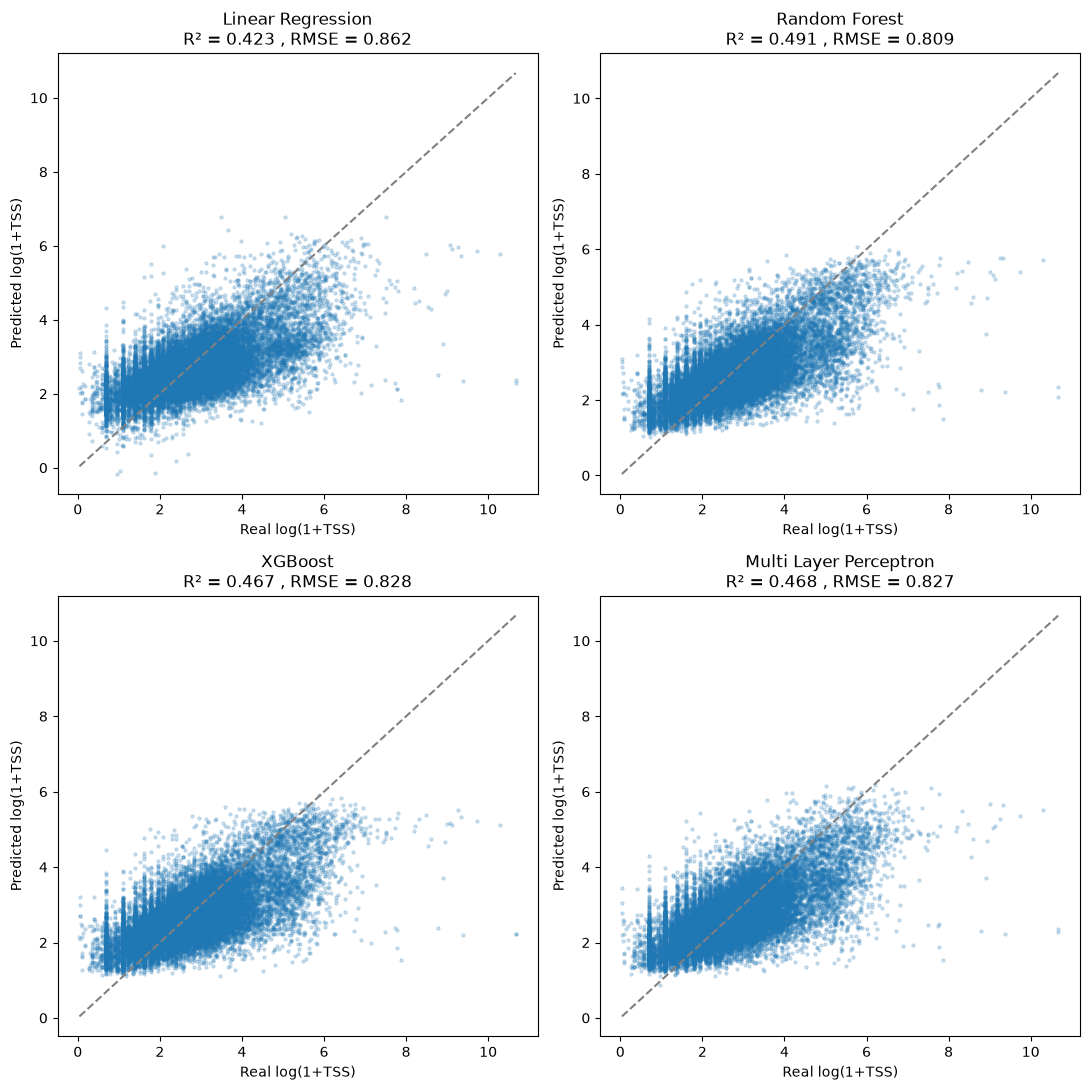

In [ ]:
### plot predicted vs real
plt.figure( figsize = (11,11) )

plt.subplot(2,2,1) 
plot_predicted_vs_real(y_true = y_test , y_predicted = y_pred_linreg , model_name = "Linear Regression") 

plt.subplot(2,2,2) 
plot_predicted_vs_real(y_true = y_test , y_predicted = y_pred_random_forest , model_name = "Random Forest") 

plt.subplot(2,2,3) 
plot_predicted_vs_real(y_true = y_test , y_predicted = y_pred_xgboost , model_name = "XGBoost") 

plt.subplot(2,2,4) 
plot_predicted_vs_real(y_true = y_test , y_predicted = y_pred_mlp , model_name = "Multi Layer Perceptron") 

plt.tight_layout()
plt.show()

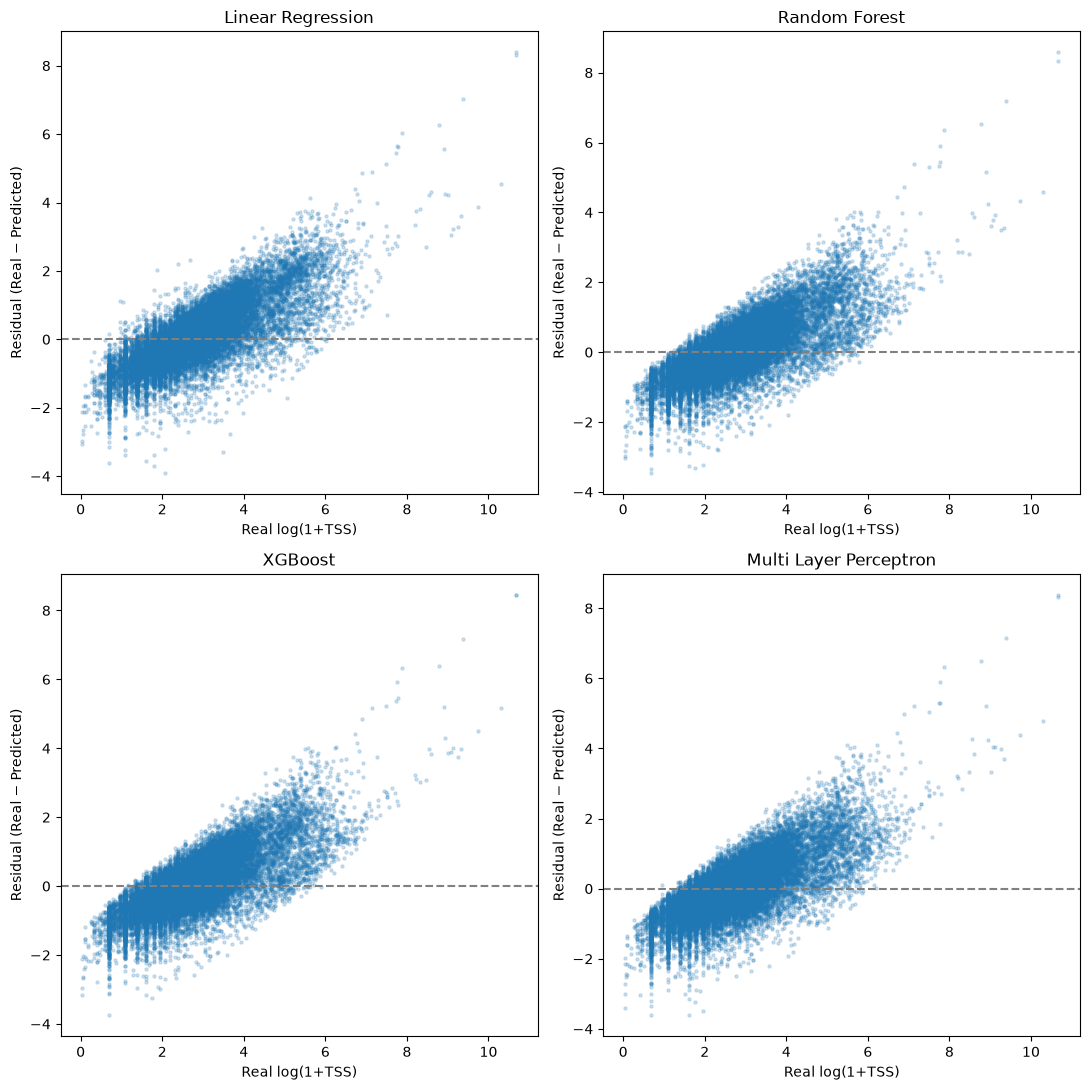

In [ ]:
### plot residual vs real
plt.figure( figsize = (11,11) )

plt.subplot(2,2,1) 
plot_residual_vs_real(y_true = y_test , y_predicted = y_pred_linreg , model_name = "Linear Regression") 

plt.subplot(2,2,2) 
plot_residual_vs_real(y_true = y_test , y_predicted = y_pred_random_forest , model_name = "Random Forest") 

plt.subplot(2,2,3) 
plot_residual_vs_real(y_true = y_test , y_predicted = y_pred_xgboost , model_name = "XGBoost") 

plt.subplot(2,2,4) 
plot_residual_vs_real(y_true = y_test , y_predicted = y_pred_mlp , model_name = "Multi Layer Perceptron") 

plt.tight_layout()
plt.show()

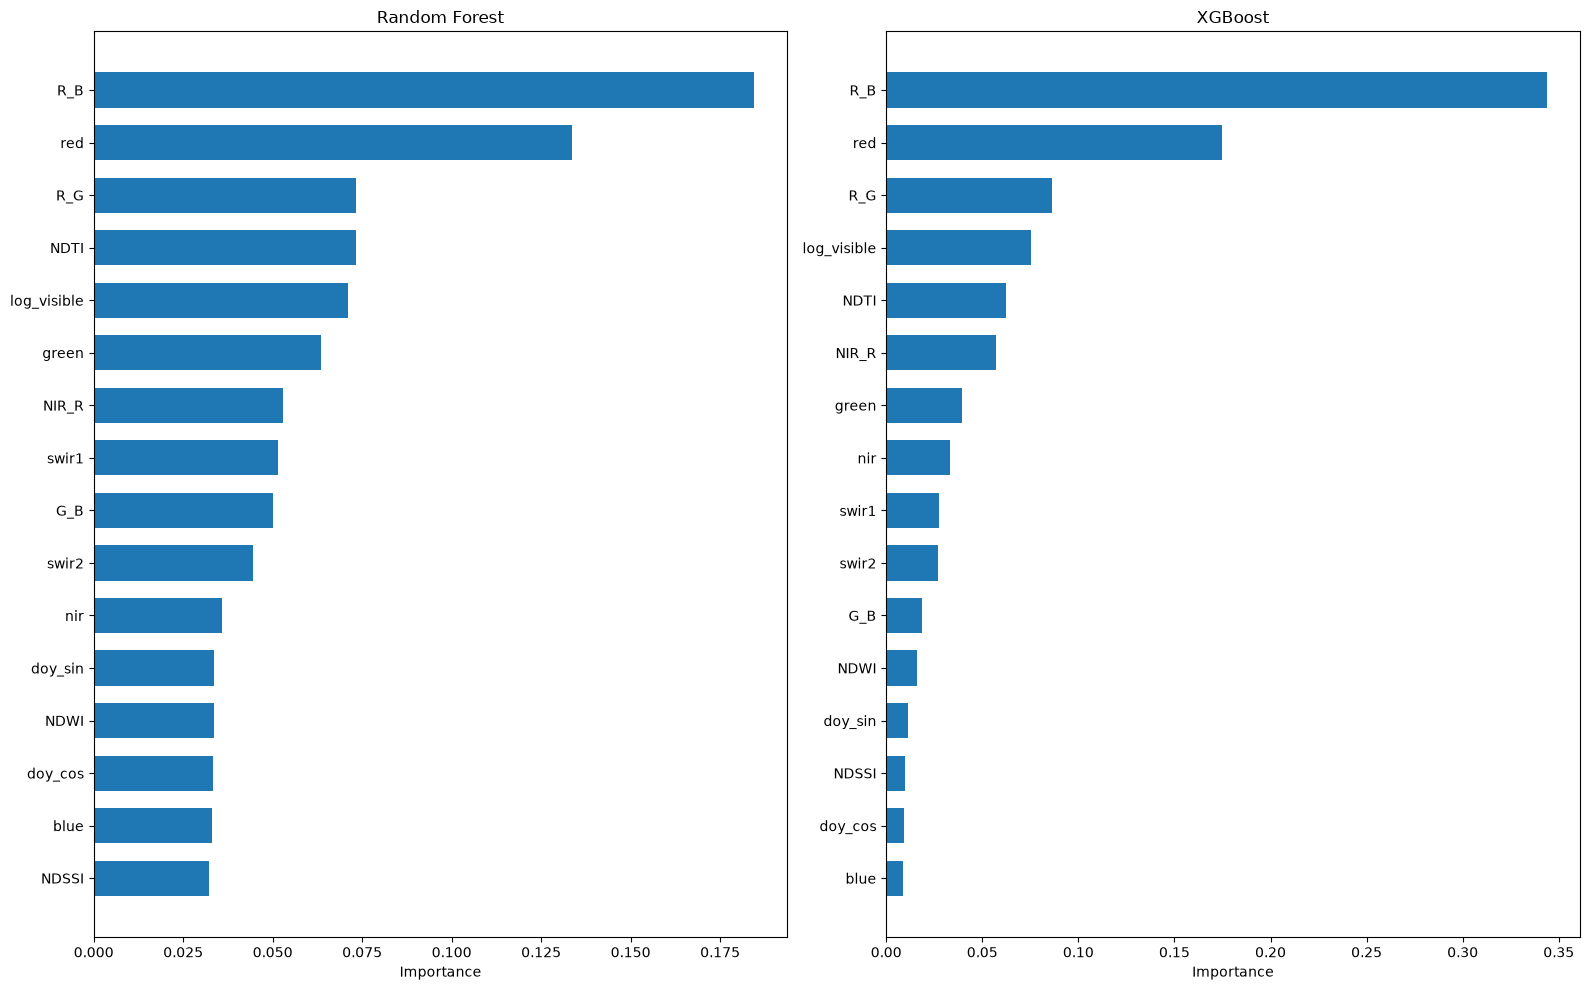

In [ ]:
### plot feature importance 

plt.figure( figsize = (16,10) )

### can only plot feature_importances_. on tree based

plt.subplot(1,2,1) 
plot_feature_importance(pipeline = random_forest_pipeline , model_name = "Random Forest") 

plt.subplot(1,2,2) 
plot_feature_importance(pipeline = xgboost_pipeline , model_name = "XGBoost") 

plt.tight_layout()
plt.show()

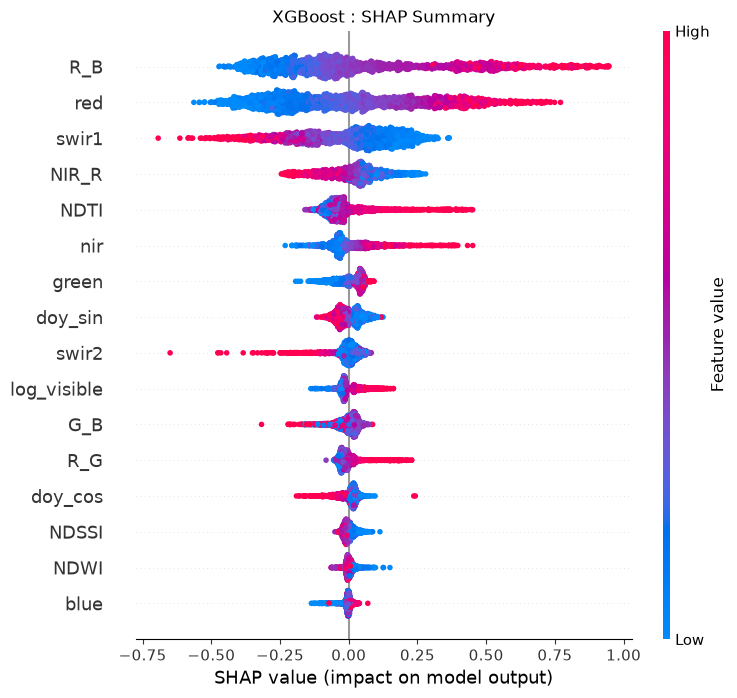

In [ ]:
### plot SHAP Summary (only on XGB is enough)
plot_shap_summary(xgboost_pipeline , "XGBoost")


### Summary from `Part IV Data Visualization`

### Visualization Summary

1. **Predicted vs Real** : `Random Forest` is the best (R² = 0.491) , followed by `MLP` / `XGBoost` (≈ 0.47) and `Linear Regression` (0.423)
> All models predict in a narrower range than the real values

2. **Residual vs Real** : All models make the same errors (low TSS over-predicted , high TSS under-predicted)
> The limitation comes from the data / features , not the model type

3. **Feature Importance** : Both RF and XGBoost rank `R_B` (red/blue ratio) and `red` as the most important features

4. **SHAP** : Higher `red` , `R_B` , `NDTI` , `nir` → higher predicted TSS
> Consistent with physics : suspended sediment reflects more red & NIR light

**Overall :** RF performs best , but all models are only moderately accurate (R² ≈ 0.5) and rely mainly on red-band reflectance

## Part V : Model Evaluation

In [ ]:
## define cross_validate parameters
from sklearn.model_selection import cross_validate

## using GroupKFold (cross validation techniques) to classify by SiteID 
group_k_fold = GroupKFold(n_splits = 5) 

## define metrics (note : error metrics given as negative values)
scoring_dict = {"R2" : "r2" , 
                "RMSE" : "neg_root_mean_squared_error" , 
                "MAE" : "neg_mean_absolute_error"}


Note : details for `scoring_dict` : [Here](https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-string-names)

In [ ]:
## define cv for all models 
estimator_lists = [baseline_lin_reg_pipeline , random_forest_pipeline , xgboost_pipeline , neural_mlp_pipeline]
cv_lists = []

for i in range(len(estimator_lists)) : 
    cv_lists.append( cross_validate(estimator = estimator_lists[i] , 
                           X = X_train , y = y_train , groups = g_train ,  # g_train = groups.iloc[train_idx] 
                           cv = group_k_fold , scoring = scoring_dict , return_train_score = True) )

cv_linreg = cv_lists[0] ; cv_random_forest = cv_lists[1] ; cv_xgboost = cv_lists[2] ; cv_neural_mlp = cv_lists[3]

In [ ]:
### print R^2 and CV for each model 

## model 1 : linear regression
print("---- Model : Linear Regression ----")
print("Train R² :" , cv_linreg["train_R2"].mean().round(3))
print("CV R²    :" , cv_linreg["test_R2"].mean().round(3) , "±" , cv_linreg["test_R2"].std().round(3))
print("CV RMSE  :" , -cv_linreg["test_RMSE"].mean().round(3))
print("CV MAE   :" , -cv_linreg["test_MAE"].mean().round(3))

---- Model : Linear Regression ----
Train R² : 0.383
CV R²    : 0.372 ± 0.032
CV RMSE  : 0.853
CV MAE   : 0.645


In [ ]:
## model 2 : random forest
print("---- Model : Random Forest ----")
print("Train R² :" , cv_random_forest["train_R2"].mean().round(3))
print("CV R²    :" , cv_random_forest["test_R2"].mean().round(3) , "±" , cv_random_forest["test_R2"].std().round(3))
print("CV RMSE  :" , -cv_random_forest["test_RMSE"].mean().round(3))
print("CV MAE   :" , -cv_random_forest["test_MAE"].mean().round(3))

---- Model : Random Forest ----
Train R² : 0.656
CV R²    : 0.453 ± 0.026
CV RMSE  : 0.796
CV MAE   : 0.598


In [ ]:
## model 3 : xgboost
print("---- Model : Extreme Gradient Boosting ----")
print("Train R² :" , cv_xgboost["train_R2"].mean().round(3))
print("CV R²    :" , cv_xgboost["test_R2"].mean().round(3) , "±" , cv_xgboost["test_R2"].std().round(3))
print("CV RMSE  :" , -cv_xgboost["test_RMSE"].mean().round(3))
print("CV MAE   :" , -cv_xgboost["test_MAE"].mean().round(3))

---- Model : Extreme Gradient Boosting ----
Train R² : 0.462
CV R²    : 0.429 ± 0.027
CV RMSE  : 0.813
CV MAE   : 0.614


In [ ]:
## model 4 : multi layer perceptron
print("---- Model : Multi Layer Perceptron ----")
print("Train R² :" , cv_neural_mlp["train_R2"].mean().round(3))
print("CV R²    :" , cv_neural_mlp["test_R2"].mean().round(3) , "±" , cv_neural_mlp["test_R2"].std().round(3))
print("CV RMSE  :" , -cv_neural_mlp["test_RMSE"].mean().round(3))
print("CV MAE   :" , -cv_neural_mlp["test_MAE"].mean().round(3))

---- Model : Multi Layer Perceptron ----
Train R² : 0.451
CV R²    : 0.427 ± 0.026
CV RMSE  : 0.815
CV MAE   : 0.615


In [ ]:
### plotting dataframe of normal and CV evaluation score
## compare normal (train on full train set , score on test set) vs CV (average of 5 folds)
compare_df = pd.DataFrame({
    "Model" : ["Linear Regression" , "Random Forest" , "XGBoost" , "Multi Layer Perceptron"] ,

    "Test R2" : [r2_score(y_test , y_pred_linreg) ,
                 r2_score(y_test , y_pred_random_forest) ,
                 r2_score(y_test , y_pred_xgboost) ,
                 r2_score(y_test , y_pred_mlp)] ,
    "CV R2"   : [cv_linreg["test_R2"].mean() ,
                 cv_random_forest["test_R2"].mean() ,
                 cv_xgboost["test_R2"].mean() ,
                 cv_neural_mlp["test_R2"].mean()] ,

    "Test RMSE" : [np.sqrt(mean_squared_error(y_test , y_pred_linreg)) ,
                   np.sqrt(mean_squared_error(y_test , y_pred_random_forest)) ,
                   np.sqrt(mean_squared_error(y_test , y_pred_xgboost)) ,
                   np.sqrt(mean_squared_error(y_test , y_pred_mlp))] ,
    "CV RMSE"   : [-cv_linreg["test_RMSE"].mean() ,      # flip sign (sklearn gives negative)
                   -cv_random_forest["test_RMSE"].mean() ,
                   -cv_xgboost["test_RMSE"].mean() ,
                   -cv_neural_mlp["test_RMSE"].mean()] ,

    "Test MAE" : [mean_absolute_error(y_test , y_pred_linreg) ,
                  mean_absolute_error(y_test , y_pred_random_forest) ,
                  mean_absolute_error(y_test , y_pred_xgboost) ,
                  mean_absolute_error(y_test , y_pred_mlp)] ,
    "CV MAE"   : [-cv_linreg["test_MAE"].mean() ,
                  -cv_random_forest["test_MAE"].mean() ,
                  -cv_xgboost["test_MAE"].mean() ,
                  -cv_neural_mlp["test_MAE"].mean()] ,
}).set_index("Model").round(3)

compare_df

,Test R2,CV R2,Test RMSE,CV RMSE,Test MAE,CV MAE
Model,,,,,,
Linear Regression,0.423,0.372,0.862,0.853,0.646,0.645
Random Forest,0.491,0.453,0.809,0.796,0.598,0.598
XGBoost,0.467,0.429,0.828,0.813,0.618,0.614
Multi Layer Perceptron,0.468,0.427,0.827,0.815,0.621,0.615


## Part VI : Model Optimization
Use the CV results from Part V as a baseline ("before") , then tune hyperparameters of each model and compare the results ("after")

From Part V (CV before tuning) :
- `Random Forest` has the best CV R² (0.453) but **overfits** (Train R² 0.656 vs CV R² 0.453 , gap ≈ 0.20)
- `XGBoost` and `MLP` slightly **underfit** (small gap ≈ 0.03 , but low score ≈ 0.43)
- `Linear Regression` is the baseline --> no hyperparameters to tune

Steps to optimize model
- Step 1 : Hyperparameter tuning with `RandomizedSearchCV`
> Randomly try several hyperparameter combinations , each one is checked with the same `GroupKFold` (5 folds , by `SiteID`) , then pick the best one

- Step 2 : Tuning direction based on Part V
> `Random Forest` : large Train/CV gap is normal for RF (deep trees are averaged) --> try both directions , more complexity gives better CV R²

> `XGBoost` : increase complexity (`max_depth` , `n_estimators` , `learning_rate`)
> `MLP` : try bigger hidden layers and different `alpha` (L2 regularization)

- Step 3 : Run CV again on the tuned models --> compare **before vs after** tuning

- Step 4 : Evaluate the best model on the **test set only once** (test set is never used during tuning to prevent data leakage)


### Step 1 : Finding best parameter from RandomizedSearchCV

In [ ]:
### Step 1 : Find Best Parameter from RamdomizedSearchCV
## (not using GridSearchCV bcz grid will try all combinations , making it too slow)
from sklearn.model_selection import RandomizedSearchCV

## create parameters
random_forest_params = {
    "model__min_samples_leaf" : [1 , 3 , 5 , 10] ,   # min rows in each leaf (smaller = deeper tree)
    "model__max_features"     : [0.33 , 0.5 , 0.7] , # % of features tried at each split (1.0 removed --> too slow)
    "model__max_depth"        : [20 , None] ,        # limit tree depth (None = no limit)
}

## XGBoost underfits --> try more complex values
xgboost_params = {
    "model__max_depth"     : [4 , 6 , 8] ,
    "model__n_estimators"  : [300 , 500 , 800] ,
    "model__learning_rate" : [0.03 , 0.05 , 0.1] ,
}

## MLP underfits --> try bigger networks
neural_mlp_params = {
    "model__hidden_layer_sizes" : [(64 , 32) , (128 , 64) , (128 , 64 , 32)] ,
    "model__alpha"              : [1e-4 , 1e-3 , 1e-2] ,
}

In [ ]:
random_forest_randsearchcv = RandomizedSearchCV(estimator = random_forest_pipeline , 
                                          param_distributions = random_forest_params , 
                                          n_iter = 4 , 
                                          cv = GroupKFold(n_splits = 3) ,
                                          scoring = "r2" , random_state = 42)


xgboost_randsearchcv = RandomizedSearchCV(estimator = xgboost_pipeline , 
                                          param_distributions = xgboost_params , 
                                          n_iter = 4 , 
                                          cv = GroupKFold(n_splits = 3) ,
                                          scoring = "r2" , random_state = 42)


## note : not gonna to random search cv on "mlp" , too slow and not efficient enough to do 


In [ ]:
### train each model to get best parameters
random_forest_randsearchcv.fit(X = X_train , y = y_train , groups = g_train)

xgboost_randsearchcv.fit(X = X_train , y = y_train , groups = g_train)

# neural_mlp_randsearchcv.fit(X = X_train , y = y_train , groups = g_train)

In [ ]:
### print best parameters
print("Random Forest :" , random_forest_randsearchcv.best_params_)
print("XGBoost       :" , xgboost_randsearchcv.best_params_)

Random Forest : {'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
XGBoost       : {'model__n_estimators': 800, 'model__max_depth': 8, 'model__learning_rate': 0.03}


### Step 2 : Tuning model with `best_params`

In [ ]:
random_forest_randsearchcv.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['blue','green','red',...,'log_visible','doy_sin','doy_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to

In [ ]:
### cross_validate 
random_forest_cv_tuned = cross_validate(estimator = random_forest_randsearchcv.best_estimator_ ,
                                        X = X_train , y = y_train , groups = g_train , 
                                        cv = group_k_fold , scoring = scoring_dict , 
                                        return_train_score = True) 

xgboost_cv_tuned = cross_validate( estimator = xgboost_randsearchcv.best_estimator_ ,
                                        X = X_train , y = y_train , groups = g_train , 
                                        cv = group_k_fold , scoring = scoring_dict , 
                                        return_train_score = True) 

In [ ]:
### compare before vs after tuning (CV 5 folds)
tuning_compare_df = pd.DataFrame({
    "Model" : ["Random Forest (before)" , "Random Forest (after)" , "XGBoost (before)" , "XGBoost (after)"] ,

    "Train R2"  : [cv_random_forest["train_R2"].mean() ,
                   random_forest_cv_tuned["train_R2"].mean() ,
                   cv_xgboost["train_R2"].mean() ,
                   xgboost_cv_tuned["train_R2"].mean()] ,
    
    "CV R2"     : [cv_random_forest["test_R2"].mean() ,
                   random_forest_cv_tuned["test_R2"].mean() ,
                   cv_xgboost["test_R2"].mean() ,
                   xgboost_cv_tuned["test_R2"].mean()] ,
    
    "CV R2 std" : [cv_random_forest["test_R2"].std() ,
                   random_forest_cv_tuned["test_R2"].std() ,
                   cv_xgboost["test_R2"].std() ,
                   xgboost_cv_tuned["test_R2"].std()] ,
    
    "CV RMSE"   : [-cv_random_forest["test_RMSE"].mean() ,      # flip sign (sklearn gives negative)
                   -random_forest_cv_tuned["test_RMSE"].mean() ,
                   -cv_xgboost["test_RMSE"].mean() ,
                   -xgboost_cv_tuned["test_RMSE"].mean()] ,
    
    "CV MAE"    : [-cv_random_forest["test_MAE"].mean() ,
                   -random_forest_cv_tuned["test_MAE"].mean() ,
                   -cv_xgboost["test_MAE"].mean() ,
                   -xgboost_cv_tuned["test_MAE"].mean()] ,
    
}).set_index("Model").round(3)

tuning_compare_df

,Train R2,CV R2,CV R2 std,CV RMSE,CV MAE
Model,,,,,
Random Forest (before),0.656,0.453,0.026,0.796,0.598
Random Forest (after),0.805,0.465,0.026,0.787,0.587
XGBoost (before),0.462,0.429,0.027,0.813,0.614
XGBoost (after),0.683,0.464,0.025,0.788,0.590


Note : Best Model = Random Forest
 
So , We'll evaluate best model on test set **only once**

In [ ]:
best_model = random_forest_randsearchcv.best_estimator_ # already trained on full X_train (refit = True)

## predict with X_test 
y_predicted_best_model = best_model.predict(X = X_test) 

## compare before vs after tuning on test set
final_df = pd.DataFrame({
    "Model"     : ["Random Forest (before)" , "Random Forest (after)"] ,
    "Test R2"   : [r2_score(y_test , y_pred_random_forest) ,
                   r2_score(y_test , y_predicted_best_model)] ,
    "Test RMSE" : [np.sqrt(mean_squared_error(y_test , y_pred_random_forest)) ,
                   np.sqrt(mean_squared_error(y_test , y_predicted_best_model))] ,
    "Test MAE"  : [mean_absolute_error(y_test , y_pred_random_forest) ,
                   mean_absolute_error(y_test , y_predicted_best_model)] ,
}).set_index("Model").round(3)

print(final_df)

                        Test R2  Test RMSE  Test MAE
Model                                               
Random Forest (before)    0.491      0.809     0.598
Random Forest (after)     0.503      0.800     0.586


### Optimization Summary

1. **Best parameters (RandomizedSearchCV)** : both models chose **more complex** settings
- `Random Forest` : `min_samples_leaf = 1` , `max_features = 0.5` , `max_depth = None`
- `XGBoost` : `n_estimators = 800` , `max_depth = 8` , `learning_rate = 0.03`

2. **CV before vs after** : `Random Forest` 0.453 → 0.465 , `XGBoost` 0.429 → 0.464 (biggest gain)
> Train R² rises more than CV R² (RF 0.656 → 0.805) , but CV still improves → the bigger gap is not harmful here

3. **Test set (used once)** : tuned `Random Forest` R² 0.491 → **0.503** , RMSE 0.809 → 0.800 , MAE 0.598 → 0.586
> MAE 0.586 in log scale → predictions are typically off by about **1.8×** the real TSS

**Overall :** Tuning gives only a small improvement (+0.01 R²) → the main limitation is the features , not the hyperparameters


## Part VII : Conclusion

**Findings**
- Best model : tuned `Random Forest` , Test R² = 0.503 on **lakes never seen in training** (split by `SiteID`)
- Non-linear models beat `Linear Regression` (0.423 → 0.503) → the reflectance–TSS relationship is non-linear , so ML is useful here
- All models compress the range : low TSS is over-predicted , high TSS is under-predicted

**Environmental Interpretation**
- `red` , `R_B` , `NDTI` and `nir` drive the predictions → suspended sediment scatters more red & NIR light , which matches water optics
- The model can show **relative** turbidity (clear vs turbid lakes) at large scale , but is not accurate enough to replace field measurements of exact TSS

**Limitations & Room for Improvement**
- Add non-satellite features : lake depth , watershed land use , rainfall before the image date
- Include sensor type (Landsat 5 / 7 / 8) , since band responses differ between satellites
- Give more weight to high-TSS samples to reduce under-prediction of very turbid water
- Wider hyperparameter search (more `n_iter`) if more compute time is available


## Extra : Webpage for Visualization

You can access webpage via this link [Click Here]()

Note
- This course have 2 projects , but in this project will focus on **Ensemble Learning** , another version will be for general assignment (5 Basic Supervised Learning Models)